# Static anomaly screening in ICU stays

This notebook uses the eICU demo to look at unusual patterns in ICU stay summaries. The original table contains repeated vital sign readings, so we first summarize each stay and then compare a robust MAD score, Isolation Forest, and an autoencoder.

The demo does not include confirmed labels for data errors. A flagged stay is therefore something a person could review, not a confirmed mistake. We also make a separate controlled test by adding a known change to some held aside examples. That tells us whether a method can rank those particular artificial changes; it does not tell us how well it finds real clinical errors.

The next notebook looks at daily reports over time and uses regression methods from our course timetable.

## 1. Imports and reproducibility

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
from sklearn.neural_network import MLPRegressor

## 2. Load the vital-sign table

In [2]:
# Download the eICU demo and put vitalPeriodic.csv.gz in data/eicu/.
# Update this path if your files are stored elsewhere.
DATA_PATH = Path("../data/eicu/vitalPeriodic.csv.gz")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/eicu/vitalPeriodic.csv.gz")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Place vitalPeriodic.csv.gz in data/eicu/ (see README.md for the source and setup)."
    )

raw = pd.read_csv(DATA_PATH, compression="gzip", low_memory=False)
print("Rows and columns:", raw.shape)
display(raw.head())
print("Columns:", raw.columns.tolist())

Rows and columns: (1634960, 19)


,vitalperiodicid,patientunitstayid,observationoffset,temperature,sao2,heartrate,respiration,cvp,etco2,systemicsystolic,systemicdiastolic,systemicmean,pasystolic,padiastolic,pamean,st1,st2,st3,icp
0,29524122,141765,1179,NaN,NaN,82.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,29557845,141765,189,NaN,97.0,76.0,30.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,29524442,141765,1169,NaN,NaN,84.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,29513052,141765,1534,NaN,NaN,92.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,29524600,141765,1164,NaN,NaN,86.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Columns: ['vitalperiodicid', 'patientunitstayid', 'observationoffset', 'temperature', 'sao2', 'heartrate', 'respiration', 'cvp', 'etco2', 'systemicsystolic', 'systemicdiastolic', 'systemicmean', 'pasystolic', 'padiastolic', 'pamean', 'st1', 'st2', 'st3', 'icp']


## 3. Explore data quality and select features

Selected vital-sign columns: ['temperature', 'sao2', 'heartrate', 'respiration', 'systemicsystolic', 'systemicdiastolic', 'systemicmean']


,count,mean,std,min,25%,50%,75%,max
temperature,112820.0,38.677957,9.780907,0.5,36.7,37.2,37.7,103.0
sao2,1441700.0,96.455192,4.725472,0.0,95.0,97.0,99.0,100.0
heartrate,1627894.0,85.464311,18.091123,0.0,72.0,84.0,97.0,257.0
respiration,1381351.0,20.118935,6.694569,0.0,16.0,19.0,23.0,188.0
systemicsystolic,226475.0,124.276839,25.743627,-44.0,107.0,122.0,140.0,349.0
systemicdiastolic,226471.0,59.338816,15.681670,-76.0,49.0,57.0,67.0,344.0
systemicmean,228400.0,80.989046,19.742098,-45.0,69.0,78.0,89.0,353.0


,missing_fraction
temperature,0.930995
systemicdiastolic,0.861482
systemicsystolic,0.861480
systemicmean,0.860302
respiration,0.155116
sao2,0.118205
heartrate,0.004322


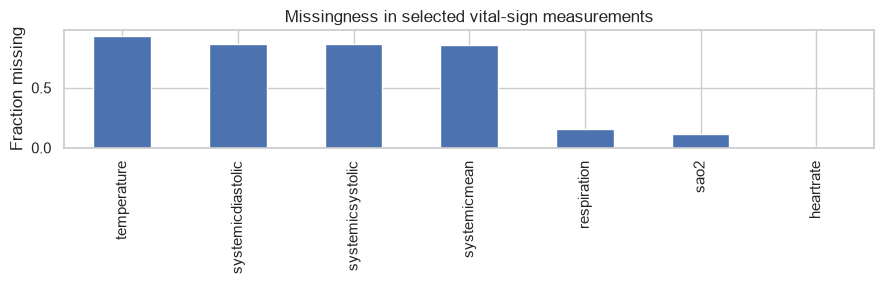

temperature: 112,820 values; min=0.5; max=103
sao2: 1,441,700 values; min=0; max=100
heartrate: 1,627,894 values; min=0; max=257
respiration: 1,381,351 values; min=0; max=188
systemicsystolic: 226,475 values; min=-44; max=349


systemicdiastolic: 226,471 values; min=-76; max=344
systemicmean: 228,400 values; min=-45; max=353
temperature: 112,820 values; min=0.5; max=103


sao2: 1,441,700 values; min=0; max=100
heartrate: 1,627,894 values; min=0; max=257
respiration: 1,381,351 values; min=0; max=188
systemicsystolic: 226,475 values; min=-44; max=349


systemicdiastolic: 226,471 values; min=-76; max=344
systemicmean: 228,400 values; min=-45; max=353


In [3]:
# The expected eICU table includes repeated observations per ICU stay.
# We retain only columns present in this version of the file.
candidate_features = [
    "temperature", "sao2", "heartrate", "respiration",
    "systemicsystolic", "systemicdiastolic", "systemicmean", "glucose"
]
id_col = "patientunitstayid"
if id_col not in raw.columns:
    raise ValueError(f"Expected stay key {id_col!r} was not found; inspect the dataset schema.")
features = [c for c in candidate_features if c in raw.columns]
if len(features) < 3:
    raise ValueError(f"Too few expected vital-sign columns were found: {features}")

print("Selected vital-sign columns:", features)
display(raw[features].describe().T)
missing = raw[features].isna().mean().sort_values(ascending=False)
display(missing.rename("missing_fraction").to_frame())
plt.figure(figsize=(9, 3))
missing.plot(kind="bar")
plt.ylabel("Fraction missing")
plt.title("Missingness in selected vital-sign measurements")
plt.tight_layout()
plt.show()

# This first pass also surfaces suspicious values and sparse fields. Do not discard
# them automatically: verify units and data conventions before calling them errors.
for feature in features:
    values = pd.to_numeric(raw[feature], errors="coerce")
    print(f"{feature}: {values.notna().sum():,} values; min={values.min():g}; max={values.max():g}")

# This first pass also surfaces suspicious values and sparse fields. Do not discard
# them automatically: verify units and data conventions before calling them errors.
for feature in features:
    values = pd.to_numeric(raw[feature], errors="coerce")
    print(f"{feature}: {values.notna().sum():,} values; min={values.min():g}; max={values.max():g}")

## 4. Summarize readings by ICU stay

We use one row per ICU stay. For each selected vital sign, we calculate its median, minimum, maximum, and number of readings. We keep stay identifiers so we can trace results, but do not give them to the models as features.

Some columns have many missing readings, and some values are zero, negative, or extreme. We keep these values for screening because they could reflect a data issue, a unit or recording convention, or a real observation. The data dictionary and units should be checked before interpreting any flagged stay.

In [4]:
work = raw[[id_col] + features].copy()
for col in features:
    work[col] = pd.to_numeric(work[col], errors="coerce")

agg = work.groupby(id_col)[features].agg(["median", "min", "max", "count"])
agg.columns = [f"{feature}_{stat}" for feature, stat in agg.columns]
stay_features = agg.reset_index()
model_cols = [c for c in stay_features.columns if c != id_col]
print("Aggregated stay-level shape:", stay_features.shape)
display(stay_features.head())
display(stay_features[model_cols].describe().T)

Aggregated stay-level shape: (2375, 29)


,patientunitstayid,temperature_median,temperature_min,temperature_max,temperature_count,sao2_median,sao2_min,sao2_max,sao2_count,heartrate_median,heartrate_min,heartrate_max,heartrate_count,respiration_median,respiration_min,respiration_max,respiration_count,systemicsystolic_median,systemicsystolic_min,systemicsystolic_max,systemicsystolic_count,systemicdiastolic_median,systemicdiastolic_min,systemicdiastolic_max,systemicdiastolic_count,systemicmean_median,systemicmean_min,systemicmean_max,systemicmean_count
0,141764,NaN,NaN,NaN,0,NaN,NaN,NaN,0,104.0,90.0,138.0,69,NaN,NaN,NaN,0,NaN,NaN,NaN,0,NaN,NaN,NaN,0,NaN,NaN,NaN,0
1,141765,NaN,NaN,NaN,0,97.0,95.0,98.0,211,86.0,72.0,138.0,449,24.0,17.0,39.0,69,NaN,NaN,NaN,0,NaN,NaN,NaN,0,NaN,NaN,NaN,0
2,143870,NaN,NaN,NaN,0,96.0,80.0,100.0,158,46.0,40.0,55.0,158,67.0,45.0,86.0,158,115.0,53.0,138.0,158,43.0,36.0,57.0,158,61.0,47.0,79.0,158
3,144815,NaN,NaN,NaN,0,99.0,96.0,100.0,176,82.0,68.0,118.0,220,17.0,6.0,42.0,220,NaN,NaN,NaN,0,NaN,NaN,NaN,0,NaN,NaN,NaN,0
4,145427,NaN,NaN,NaN,0,96.0,89.0,100.0,126,64.0,49.0,85.0,238,16.0,5.0,41.0,126,NaN,NaN,NaN,0,NaN,NaN,NaN,0,NaN,NaN,NaN,0


,count,mean,std,min,25%,50%,75%,max
temperature_median,170.0,38.527985,9.481005,33.40,36.700,37.2,37.600,100.9
temperature_min,170.0,34.166229,11.284807,0.50,31.775,35.5,36.300,97.9
temperature_max,170.0,39.482735,9.561598,34.75,37.500,38.0,38.433,103.0
temperature_count,2375.0,47.503158,278.473120,0.00,0.000,0.0,0.000,5259.0
sao2_median,2330.0,96.664378,3.448327,0.00,95.000,97.0,98.000,100.0
sao2_min,2330.0,81.293562,17.268660,0.00,77.000,87.0,92.000,100.0
sao2_max,2330.0,99.474249,1.379628,71.00,100.000,100.0,100.000,100.0
sao2_count,2375.0,607.031579,948.384340,0.00,160.500,321.0,703.000,12990.0
heartrate_median,2364.0,83.136844,16.300480,6.00,71.000,82.0,94.000,151.0
heartrate_min,2364.0,62.310491,21.399551,0.00,54.000,64.0,74.000,142.0


## 5. Prepare numeric features

In [5]:
X_raw = stay_features[model_cols].replace([np.inf, -np.inf], np.nan)
# Remove entirely empty features, then impute remaining missing values with medians.
usable_cols = X_raw.columns[X_raw.notna().any(axis=0)].tolist()
X_raw = X_raw[usable_cols]
imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(imputer.fit_transform(X_raw), columns=usable_cols)
scaler = RobustScaler()
X = pd.DataFrame(scaler.fit_transform(X_imputed), columns=usable_cols)
print("Model matrix:", X.shape)
print("Missing after imputation:", int(X.isna().sum().sum()))

Model matrix:

 (2375, 28)
Missing after imputation: 0


## 6. Fit Isolation Forest and an autoencoder

For each feature, the robust z score is \(z=(x-\mathrm{median}(x))/(1.4826\,\mathrm{MAD})\), where MAD is the median absolute deviation. We use the largest absolute feature score for each stay as a simple baseline. This checks features one at a time. Isolation Forest looks for records that are easy to separate in the feature space, while the autoencoder scores how difficult each stay is to reconstruct. All three methods are unsupervised in this analysis: none is trained on a confirmed clinical error label.

We use the same 5% review limit for each method so their shortlists can be compared. The methods may still select different stays.

In [6]:
# Robust univariate baseline: maximum absolute median/MAD score.
med = X_imputed.median(axis=0)
mad = (X_imputed - med).abs().median(axis=0).replace(0, np.nan)
robust_z = ((X_imputed - med) / (1.4826 * mad)).replace([np.inf, -np.inf], np.nan).fillna(0)
baseline_score = robust_z.abs().max(axis=1).to_numpy()

contamination = 0.05
if_model = IsolationForest(
    n_estimators=200, contamination=contamination,
    random_state=RANDOM_STATE, n_jobs=-1
)
if_model.fit(X)
if_score = -if_model.decision_function(X)

# A narrow hidden layer compresses and reconstructs the stay features.
hidden_width = max(2, min(8, X.shape[1] // 2))
autoencoder = MLPRegressor(hidden_layer_sizes=(hidden_width,), activation="relu",
                           solver="adam", max_iter=500, early_stopping=True,
                           random_state=RANDOM_STATE)
autoencoder.fit(X, X)
ae_score = np.mean((X.to_numpy() - autoencoder.predict(X)) ** 2, axis=1)

results = stay_features[[id_col]].copy()
results["baseline_score"] = baseline_score
results["iforest_score"] = if_score
results["autoencoder_score"] = ae_score
results["baseline_flag"] = results.baseline_score >= results.baseline_score.quantile(1-contamination)
results["iforest_flag"] = if_model.predict(X) == -1
results["autoencoder_flag"] = results.autoencoder_score >= results.autoencoder_score.quantile(1-contamination)
print("Flag counts:")
display(results[["baseline_flag", "iforest_flag", "autoencoder_flag"]].sum().rename("flagged_stays").to_frame())
print("Overlap:", int((results.baseline_flag & results.iforest_flag).sum()))
display(results.sort_values("iforest_score", ascending=False).head(10))

Flag counts:


,flagged_stays
baseline_flag,119
iforest_flag,119
autoencoder_flag,119


Overlap: 46


,patientunitstayid,baseline_score,iforest_score,autoencoder_score,baseline_flag,iforest_flag,autoencoder_flag
1545,2416376,39.459293,0.210439,317.447147,True,True,True
1599,2559053,8.318719,0.191795,351.162197,False,True,True
387,521456,40.117950,0.178768,995.304599,True,True,True
1942,2846485,12.666493,0.156670,112.947404,True,True,False
2283,3163374,20.279056,0.155661,258.020313,True,True,True
186,263279,16.862269,0.149299,582.776152,True,True,True
189,264276,10.904267,0.148394,204.721746,True,True,False
531,741996,12.536421,0.139605,353.757580,True,True,True
1590,2552038,14.591800,0.139179,983.133391,True,True,True
1556,2436616,6.706908,0.136229,261.105788,False,True,True


## 7. Controlled evaluation with synthetic corruptions

The eICU demo has no confirmed anomaly labels for this task, so we use a controlled test. We split the stays into training and test groups and fit preprocessing and models using only the training group. For each test stay, we keep one unchanged copy and make another copy with an eight MAD shift in one randomly selected feature. We then use the known changed or unchanged status only to calculate the ranking measures.

This test checks how well each method ranks the artificial changes we introduced. It does not estimate how many real clinical records contain errors.

In [7]:
from sklearn.model_selection import train_test_split

X_train_raw, X_test_raw = train_test_split(
    X_raw, test_size=0.30, random_state=RANDOM_STATE
)
# Fit imputation/scaling on training rows only for this evaluation.
eval_imputer = SimpleImputer(strategy="median")
train_imp = eval_imputer.fit_transform(X_train_raw)
test_imp = eval_imputer.transform(X_test_raw)
train_frame = pd.DataFrame(train_imp, columns=usable_cols)
test_frame = pd.DataFrame(test_imp, columns=usable_cols)
eval_scaler = RobustScaler().fit(train_frame)
train_scaled = eval_scaler.transform(train_frame)
test_scaled = eval_scaler.transform(test_frame)

eval_if = IsolationForest(n_estimators=200, contamination=contamination,
                          random_state=RANDOM_STATE, n_jobs=-1)
eval_if.fit(train_scaled)
eval_ae = MLPRegressor(hidden_layer_sizes=(max(2, min(8, train_scaled.shape[1] // 2)),),
                       activation="relu", solver="adam", max_iter=500,
                       early_stopping=True, random_state=RANDOM_STATE)
eval_ae.fit(train_scaled, train_scaled)

test_df = pd.DataFrame(test_imp, columns=usable_cols)
train_df = pd.DataFrame(train_imp, columns=usable_cols)
med_train = train_df.median()
mad_train = (pd.DataFrame(train_imp, columns=usable_cols) - med_train).abs().median().replace(0, np.nan)

clean = test_df.copy()
corrupt = test_df.copy()
rng = np.random.default_rng(RANDOM_STATE)
row_ids = rng.permutation(len(corrupt))
col_ids = rng.integers(0, corrupt.shape[1], size=len(corrupt))
for row, col in zip(row_ids, col_ids):
    col_name = corrupt.columns[col]
    scale = float(mad_train[col_name])
    if not np.isfinite(scale) or scale == 0:
        scale = float(pd.Series(train_imp[:, col]).std() or 1.0)
    # Push one feature far from its training median; alternate directions.
    direction = -1 if rng.random() < 0.5 else 1
    corrupt.iat[row, col] = med_train[col_name] + direction * 8 * scale

eval_X = pd.concat([clean, corrupt], ignore_index=True)
y_eval = np.r_[np.zeros(len(clean), dtype=int), np.ones(len(corrupt), dtype=int)]
eval_scaled = eval_scaler.transform(eval_X)
eval_if_scores = -eval_if.decision_function(eval_scaled)
eval_ae_scores = np.mean((eval_scaled - eval_ae.predict(eval_scaled)) ** 2, axis=1)
eval_z = ((eval_X - med_train) / (1.4826 * mad_train)).replace([np.inf, -np.inf], np.nan).fillna(0)
eval_baseline_scores = eval_z.abs().max(axis=1).to_numpy()

def summarize_scores(name, scores):
    return {"method": name,
            "roc_auc": roc_auc_score(y_eval, scores),
            "average_precision": average_precision_score(y_eval, scores)}

eval_summary = pd.DataFrame([
    summarize_scores("MAD baseline", eval_baseline_scores),
    summarize_scores("Isolation Forest", eval_if_scores),
    summarize_scores("Autoencoder", eval_ae_scores),
])
display(eval_summary)
print("Evaluation pairs:", len(clean), "clean +", len(corrupt), "synthetically corrupted")

,method,roc_auc,average_precision
0,MAD baseline,0.652697,0.648316
1,Isolation Forest,0.676261,0.601441
2,Autoencoder,0.812778,0.801167


Evaluation pairs: 713 clean + 713 synthetically corrupted


## 8. Inspect flagged stays and interpret cautiously

In [8]:
flagged_ids = results.loc[results.iforest_flag, id_col]
flagged = stay_features[stay_features[id_col].isin(flagged_ids)].copy()
flagged = flagged.merge(results[[id_col, "baseline_score", "iforest_score"]], on=id_col)
display(flagged.sort_values("iforest_score", ascending=False).head(15))

# Show the feature summaries most different from the overall median in the top flags.
top = flagged.sort_values("iforest_score", ascending=False).head(10)
summary_cols = [c for c in model_cols if c.endswith("_median")]
if len(top) and summary_cols:
    display(top[[id_col] + summary_cols].T)

,patientunitstayid,temperature_median,temperature_min,temperature_max,temperature_count,sao2_median,sao2_min,sao2_max,sao2_count,heartrate_median,heartrate_min,heartrate_max,heartrate_count,respiration_median,respiration_min,respiration_max,respiration_count,systemicsystolic_median,systemicsystolic_min,systemicsystolic_max,systemicsystolic_count,systemicdiastolic_median,systemicdiastolic_min,systemicdiastolic_max,systemicdiastolic_count,systemicmean_median,systemicmean_min,systemicmean_max,systemicmean_count,baseline_score,iforest_score
69,2416376,NaN,NaN,NaN,0,99.0,64.0,100.0,12782,105.0,74.0,151.0,12677,24.0,0.0,58.0,12863,113.0,4.0,300.0,5520,54.0,-5.0,300.0,5520,71.0,-2.0,300.0,5520,39.459293,0.210439
75,2559053,36.5,35.1,38.2,2626,99.0,13.0,100.0,2648,107.0,39.0,161.0,2690,15.0,0.0,28.0,2697,114.0,-11.0,300.0,2653,54.0,-14.0,300.0,2653,78.0,-13.0,300.0,2653,8.318719,0.191795
20,521456,NaN,NaN,NaN,0,98.0,65.0,100.0,12990,79.0,48.0,124.0,13109,25.0,0.0,44.0,12022,113.0,48.0,261.0,6046,46.0,27.0,186.0,6046,67.0,3.0,201.0,6241,40.117950,0.178768
88,2846485,38.1,24.4,41.9,2644,96.0,34.0,100.0,4321,97.0,65.0,158.0,4579,25.0,10.0,43.0,4098,111.0,48.0,235.0,1218,68.0,29.0,159.0,1218,83.0,-8.0,187.0,1225,12.666493,0.156670
110,3163374,NaN,NaN,NaN,0,99.0,31.0,100.0,6725,69.0,24.0,104.0,6780,23.0,9.0,40.0,6752,171.0,68.0,266.0,5211,48.0,34.0,121.0,5211,77.0,19.0,212.0,5242,20.279056,0.155661
12,263279,NaN,NaN,NaN,0,72.0,52.0,94.0,13,86.0,67.0,140.0,13,38.0,13.0,101.0,13,29.5,20.0,32.0,4,-4.5,-16.0,13.0,4,19.0,6.0,25.0,7,16.862269,0.149299
13,264276,NaN,NaN,NaN,0,94.0,77.0,100.0,3305,84.0,44.0,184.0,3320,21.0,9.0,128.0,3320,125.0,-3.0,236.0,2556,61.0,-3.0,230.0,2556,80.0,-3.0,233.0,2556,10.904267,0.148394
24,741996,NaN,NaN,NaN,0,94.0,78.0,100.0,3848,95.0,54.0,142.0,4816,21.0,11.0,41.0,4381,114.0,22.0,194.0,4429,53.0,15.0,121.0,4429,71.0,3.0,349.0,4441,12.536421,0.139605
73,2552038,NaN,NaN,NaN,0,95.0,36.0,100.0,4929,114.0,0.0,145.0,5018,24.0,0.0,46.0,1103,113.0,39.0,208.0,4003,51.0,22.0,184.0,4003,70.0,0.0,269.0,4217,14.591800,0.139179
71,2436616,37.4,24.4,38.9,36,93.0,44.0,100.0,2439,81.0,43.0,119.0,2454,26.0,0.0,52.0,724,126.0,31.0,300.0,1753,64.0,21.0,300.0,1753,86.0,23.0,300.0,1753,6.706908,0.136229


,69,75,20,88,110,12,13,24,73,71
patientunitstayid,2416376.0,2559053.0,521456.0,2846485.0,3163374.0,263279.0,264276.0,741996.0,2552038.0,2436616.0
temperature_median,NaN,36.5,NaN,38.1,NaN,NaN,NaN,NaN,NaN,37.4
sao2_median,99.0,99.0,98.0,96.0,99.0,72.0,94.0,94.0,95.0,93.0
heartrate_median,105.0,107.0,79.0,97.0,69.0,86.0,84.0,95.0,114.0,81.0
respiration_median,24.0,15.0,25.0,25.0,23.0,38.0,21.0,21.0,24.0,26.0
systemicsystolic_median,113.0,114.0,113.0,111.0,171.0,29.5,125.0,114.0,113.0,126.0
systemicdiastolic_median,54.0,54.0,46.0,68.0,48.0,-4.5,61.0,53.0,51.0,64.0
systemicmean_median,71.0,78.0,67.0,83.0,77.0,19.0,80.0,71.0,70.0,86.0


## Interpreting the results

Use the ROC-AUC and average precision values to compare how well the methods ranked the changed examples. Consider why the single feature MAD baseline might miss patterns across several features and why Isolation Forest or the autoencoder might give different rankings. A more flexible method can capture more complicated patterns, but that does not guarantee it will work better on new data. The synthetic test gives us a controlled comparison; because the demo has no confirmed error labels, we cannot draw conclusions about real registry errors from it.

## References

Johnson, A., Pollard, T., Badawi, O., & Raffa, J. (2019). *eICU Collaborative Research Database Demo (version 2.0).* PhysioNet. https://doi.org/10.13026/gxmm-es70

Dataset page: https://physionet.org/content/eicu-crd-demo/2.0/